# Qubit chip demo: eigenmode and S-parameters

Simulate a **5.4 × 3.1 mm QPDK chip** with two qubits, readout resonators,
a shared bus, and vortex-trapping fill. Model each qubit with a lumped
Josephson inductance, find four eigenmodes above 2 GHz, and sweep S11 and
S21 over 2–10 GHz using **4 µm refinement** near the metal. Each simulation object
generates its own mesh with the same settings.
The [two-qubit layout](https://github.com/gdsfactory/gsim/blob/main/nbs/data/qpdk/two_qubit_straight_bus.pic.yml)
is a straight-bus variant of QPDK's filled test chip.

**Requirements:**

- QPDK: `uv pip install -U qpdk`
- [GDSFactory+](https://gdsfactory.com) account for cloud simulation

The model uses planar PEC metal on silicon with vacuum above and reflecting
PMC outer boundaries. Linearized junction inductances bridge the qubit pads,
and both launcher ports have matched 50 Ω loads, so the eigenmode Q includes
port loading. The inductances are illustrative; set them to your device values.
These are linearized resonances; predicting the anharmonic qubit transition
requires circuit quantization. Lengths are in µm; frequencies below are in GHz.

In [ ]:
from pathlib import Path

import gdsfactory as gf
import klayout.db as kdb
import pandas as pd
from qpdk import PDK
from qpdk.cells.chip import chip_edge
from qpdk.tech import (
    LAYER,
    LAYER_STACK,
    get_etch_section,
    material_properties,
    routing_strategies,
)
from qpdk.utils import apply_additive_metals, fill_magnetic_vortices

from gsim.common.polygon_utils import simplify_polygon
from gsim.common.stack import Layer, LayerStack
from gsim.palace import DrivenSim, EigenmodeSim

PDK.activate()

### Settings

This chip uses 4 µm refinement near metal and a coarser 300 µm mesh
away from it. Refinement is local; the whole chip is not meshed at 4 µm.
The narrowest conductor features are also 2 µm, so compare finer meshes
before relying on resonance frequencies or Q.

The mesh cells below print the element counts for the geometry with junction
sheets. Exporting four eigenmode fields increases the result archive size.

In [ ]:
refined_mesh_size_um = 4.0
max_mesh_size_um = 300.0
curve_tolerance_um = 0.1
chip_padding_um = 50.0
chip_edge_width_um = 100.0
port_length_um = 10.0

# The default double-pad transmons have 15 µm gaps along Y in this layout.
junction_gap_um = 15.0
junction_sheet_width_um = 2.0
# Illustrative effective junction/SQUID inductances; replace with device values.
junction_inductances_h = {"qubit1_jj": 15e-9, "qubit2_jj": 18e-9}
# Optional missing junction capacitance only; pad capacitance is in the geometry.
junction_capacitance_f = 0.0

eigenmode_target_ghz = 2.0
num_eigenmodes = 4
driven_fmin_ghz = 2.0
driven_fmax_ghz = 10.0
driven_num_points = 10001
driven_adaptive_tol = 1e-3
driven_adaptive_max_samples = 40

### Build the chip

Add vortex-trapping fill and leave 50 µm of ground between the layout,
including the launchers, and the 100 µm-wide etched chip-edge frame.

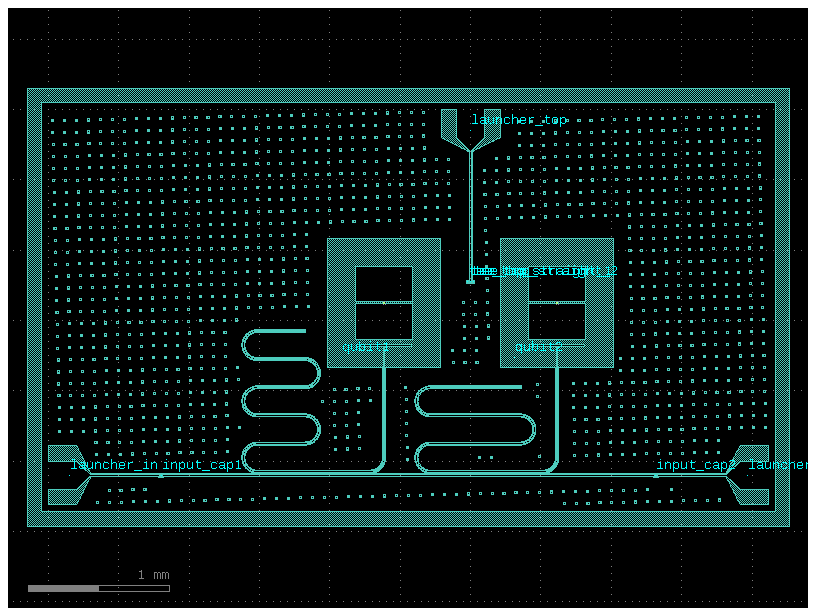

In [ ]:
notebook_dir = Path("nbs") if Path("nbs").is_dir() else Path.cwd()
port_layout = gf.read.from_yaml(
    notebook_dir / "data/qpdk/two_qubit_straight_bus.pic.yml",
    routing_strategies=routing_strategies,
)
chip_bounds = port_layout.dbbox().enlarged(chip_padding_um + chip_edge_width_um)
filled_layout = gf.Component()
filled_layout << fill_magnetic_vortices(
    component=port_layout,
    rectangle_size=(15.0, 15.0),
    gap=70.0,
    stagger=2,
)
edge = filled_layout << chip_edge(
    size=(chip_bounds.width(), chip_bounds.height()),
    width=chip_edge_width_um,
    layer=LAYER.M1_ETCH,
)
edge.dmove((chip_bounds.left, chip_bounds.bottom))
chip = apply_additive_metals(filled_layout)
chip.plot()

### Convert the etch mask to metal

Subtract the etch mask from the chip footprint and simplify curved boundaries.
Copy the two bus ports from the launcher pads and add a narrow lumped-port
sheet across each qubit pad gap. The QPDK `junction` placement ports supply the
centers; their orientation is perpendicular to the pad gap, so explicitly use
90° along Y. Keep the metal gap open: the sheet is an impedance boundary.

In [ ]:
layout = chip.kdb_cell.layout()
etch = kdb.Region(chip.kdb_cell.begin_shapes_rec(layout.layer(*LAYER.M1_ETCH))).merged()
footprint = kdb.Region(etch.bbox())
if curve_tolerance_um > 0:
    etch = kdb.Region(
        [simplify_polygon(p, tolerance=curve_tolerance_um) for p in etch.each()]
    ).merged()
metal = footprint - etch

mesh_layers = {"M1": (201, 0), "SUBSTRATE": (202, 0), "VACUUM": (203, 0)}
mesh_component = gf.Component()
for name, region in (("M1", metal), ("SUBSTRATE", footprint), ("VACUUM", footprint)):
    mesh_component.kdb_cell.shapes(
        mesh_component.kcl.layout.layer(*mesh_layers[name])
    ).insert(region)

# Keep the exported ports on the wide launcher pads.
for port_name in ("o1", "o2"):
    mesh_component.add_port(name=port_name, port=port_layout.ports[port_name])

# Bridge the two M1 electrodes at each junction center, along the pad-gap axis.
for qubit_name in ("qubit1", "qubit2"):
    junction = port_layout.insts[qubit_name].ports["junction"]
    mesh_component.add_port(
        name=f"{qubit_name}_jj",
        center=tuple(junction.dcenter),
        width=junction_sheet_width_um,
        orientation=90,
        layer=mesh_layers["M1"],
        port_type="electrical",
    )

### Define the stack and ports

Use QPDK's silicon and vacuum thicknesses, with the PEC sheet at `z=0`.
The CPW ports span the launcher gaps and remain inside the signal pads.
Each unexcited junction port has a lumped inductance in parallel with any
optional junction capacitance, with no resistive load. Both simulations use
the same junction elements. The pad capacitance is already included by the
metal geometry; do not add it again as a lumped capacitance.

For a first estimate, use $f_{\mathrm{lin}} \approx 1/(2\pi\sqrt{L_J C_{\mathrm{eff}}})$.
For a SQUID, supply its effective inductance at the chosen flux bias.

In [ ]:
stack = LayerStack(pdk_name="qpdk")
for name, zmin, zmax, material, layer_type in (
    (
        "SUBSTRATE",
        -LAYER_STACK.layers["Substrate"].thickness,
        0.0,
        "silicon",
        "dielectric",
    ),
    ("M1", 0.0, 0.0, "niobium", "conductor"),
    ("VACUUM", 0.0, LAYER_STACK.layers["Vacuum"].thickness, "vacuum", "dielectric"),
):
    stack.layers[name] = Layer(
        name=name,
        gds_layer=mesh_layers[name],
        zmin=zmin,
        zmax=zmax,
        thickness=zmax - zmin,
        material=material,
        layer_type=layer_type,
    )
stack.dielectrics = [
    dict(
        name=layer.name.lower(),
        zmin=layer.zmin,
        zmax=layer.zmax,
        material=layer.material,
    )
    for layer in stack.layers.values()
    if layer.layer_type == "dielectric"
]
stack.materials = {
    "silicon": {
        "type": "dielectric",
        "permittivity": material_properties["Si"]["relative_permittivity"],
        "loss_tangent": material_properties["Si"]["loss_tangent"],
    },
    "vacuum": {"type": "dielectric", "permittivity": 1.0},
    "niobium": {"type": "conductor"},
}

In [ ]:
eigenmode_sim = EigenmodeSim(absorbing_boundary=False)
driven_sim = DrivenSim(absorbing_boundary=False)

for sim in (eigenmode_sim, driven_sim):
    sim.set_geometry(mesh_component.copy())
    sim.set_stack(stack)
    sim.solver.linear.tolerance = 1e-9
    for port_name, inductance_h in junction_inductances_h.items():
        sim.add_port(
            port_name,
            layer="M1",
            geometry="inplane",
            length=junction_gap_um,
            offset=0.0,
            inductance=inductance_h,
            capacitance=junction_capacitance_f,
            excited=False,
        )
    for port_name in ("o1", "o2"):
        port = port_layout.ports[port_name]
        sim.add_cpw_port(
            port_name,
            layer="M1",
            s_width=float(port.dwidth),
            gap_width=get_etch_section(port.info["cross_section"]).width,
            length=port_length_um,
            offset=port_length_um / 2,
            impedance=50.0,
            excited=sim is driven_sim and port_name == "o1",
        )

eigenmode_sim.set_eigenmode(
    num_modes=num_eigenmodes,
    target=eigenmode_target_ghz * 1e9,
    save=num_eigenmodes,
)

### Generate the eigenmode mesh

Each simulation generates its own mesh using the same geometry and 4 µm
refinement. Inspect all four port surfaces before submitting the eigenmode
job: `P1` and `P2` are the launcher ports; `P3` and `P4` are the junction sheets.
Each junction sheet must touch both pad edges and remain clear of other metal.
The generated junction entries in `Boundaries.LumpedPort` should contain `L`
(and `C` if specified), with no nonzero `R`.

The simulation API requires a mesh output directory for each object.
Cloud downloads use gsim's default `sim-data-<job-name>` folders.
Both objects use `absorbing_boundary=False` for reflecting PMC outer boundaries.

In [ ]:
eigenmode_sim.set_output_dir("palace-qpdk-chip/eigenmode")
eigenmode_mesh = eigenmode_sim.mesh(
    refined_mesh_size=refined_mesh_size_um,
    max_mesh_size=max_mesh_size_um,
    fmax=driven_fmax_ghz * 1e9,
    planar_conductors=True,
)
print(f"Tetrahedral elements: {eigenmode_mesh.mesh_stats['tetrahedra']:,}")

Small conductor feature detected (2.000 um) may be under-resolved by refined_mesh_size=4.000 um. The heuristic target is <= 1.000 um (2 cells/feature). Reduce refined_mesh_size; auto_size=True preserves an explicit size.


Tetrahedral elements: 1,375,108


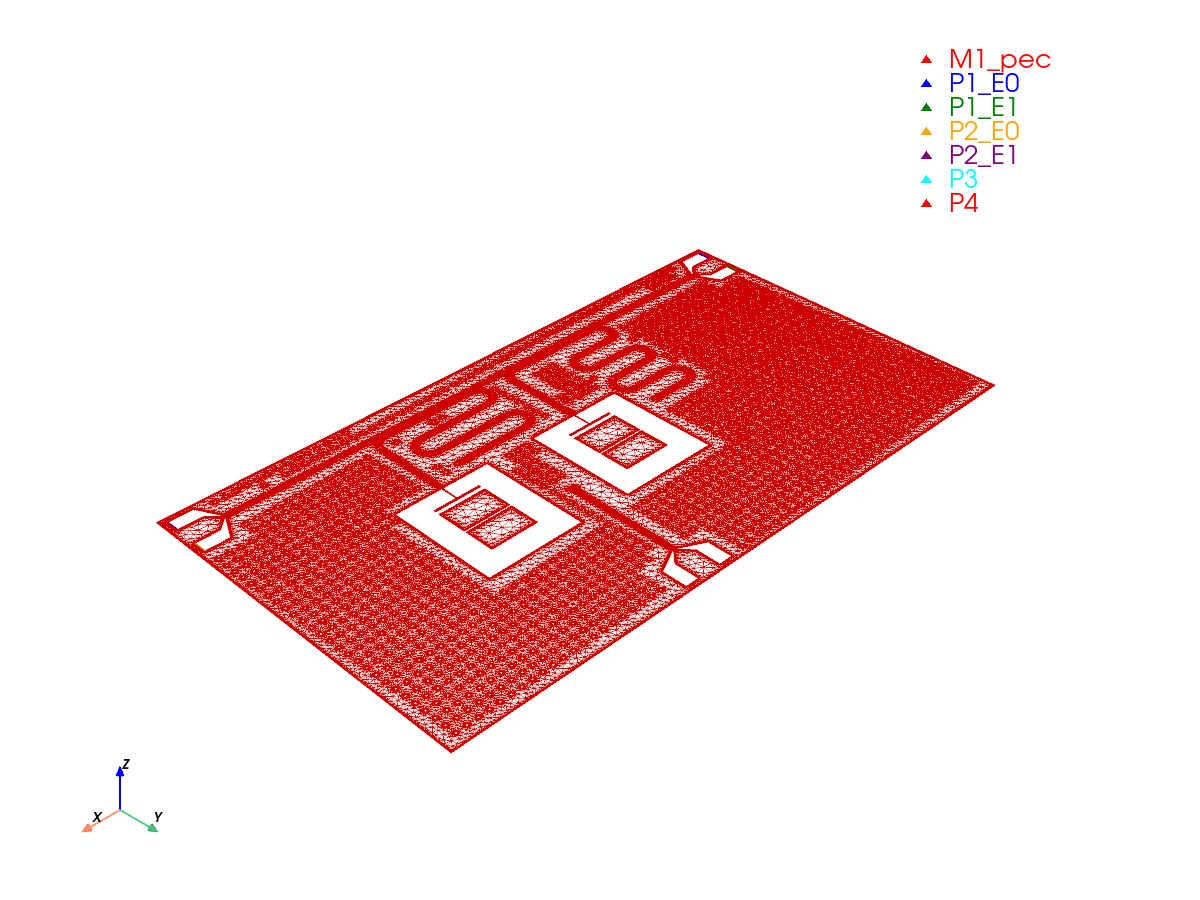

In [ ]:
eigenmode_sim.plot_mesh(
    show_groups=["M1", "P1", "P2", "P3", "P4"],
    interactive=False,
)

### Run the eigenmode simulation

Run the eigenmode object on GDSFactory+ cloud. Its `.run()` method prepares
the configuration, reuses a completed job when the inputs match, and downloads
the results. Export all four mode fields for identifying qubit, resonator,
and bus modes. Inspect the fields and `port-EPR.csv` junction participations
to distinguish qubit-like modes; mode order alone is insufficient. Set the
search target below the expected qubit frequencies and increase the number
of modes if the band of interest is not covered.

In [ ]:
eigenmode_results = eigenmode_sim.run(check_cache=True)

  palace-d5757509  [####################] 100%  complete  elapsed 26m 56s
Extracting results.tar.gz...
Downloaded 65 files to /Users/vahid/doplaydo/gsim/nbs/sim-data-palace-d5757509


### Junction energy-participation ratios

Print each mode's frequency, Q, and junction participation magnitude |p|.
Palace's `port-EPR.csv` contains signed energy-participation ratios; their
magnitudes indicate junction involvement. Values near one suggest a qubit-like
mode, while small values indicate weak involvement of that junction. The table
uses junction names from the mesh metadata and matches results by mode number.
Use it with the field maps to identify modes before choosing driven sweep windows.

In [ ]:
eigenmodes = pd.read_csv(eigenmode_results["eig.csv"], skipinitialspace=True)
eigenmodes.columns = eigenmodes.columns.str.strip()
print(
    f"Converged eigenmodes: {len(eigenmodes)} / "
    f"{eigenmode_sim.solver.eigenmode.num_modes} requested"
)

junction_epr = pd.read_csv(eigenmode_results["port-EPR.csv"], skipinitialspace=True)
junction_epr.columns = junction_epr.columns.str.strip()
junction_columns = {
    f"p[{port['portnumber']}]": f"|p| {port['name']}"
    for port in eigenmode_mesh.port_info
    if port["name"] in junction_inductances_h
}
mode_summary = eigenmodes[["m", "Re{f} (GHz)", "Q"]].join(
    junction_epr.set_index("m")[list(junction_columns)]
    .abs()
    .rename(columns=junction_columns),
    on="m",
    validate="one_to_one",
)
mode_summary = mode_summary.rename(
    columns={"m": "Mode", "Re{f} (GHz)": "Frequency (GHz)"}
)
print(mode_summary.to_string(index=False, float_format=lambda value: f"{value:.6g}"))

Converged eigenmodes: 5 / 4 requested
 Mode  Frequency (GHz)       Q  |p| qubit1_jj  |p| qubit2_jj
    1          3.87819  402723    3.12763e-06       0.995955
    2          4.24574  402607        0.99502    3.02181e-06
    3          7.84515 3350.38    1.51355e-07    1.69232e-07
    4          9.07594 31222.9    1.63538e-05    2.69436e-06
    5          10.4406  4421.8    1.82528e-09    1.49241e-06


### Visualize the eigenmode fields

Plot a top view of each saved mode 1 µm above the metal at `z=0`.
`eig.csv` can list more modes than the configured `save` count, but only
saved modes have ParaView fields. `load_fields(..., mode=...)` selects the
one-based mode number. Combine the real and imaginary electric fields to show
the phase-independent magnitude $|E| = \sqrt{\sum_i (E_{i,\mathrm{real}}^2 + E_{i,\mathrm{imag}}^2)}$.

Eigenmode amplitudes have arbitrary normalization. Each plot uses its own
color scale, clipped at the 98th percentile to reveal weaker features.
Compare where the field concentrates around qubit pads, readout resonators,
and the bus; use junction participation to confirm qubit-like modes.
Change `field_slice_z_um` to inspect another height. Modes are loaded one at
a time to limit memory use.


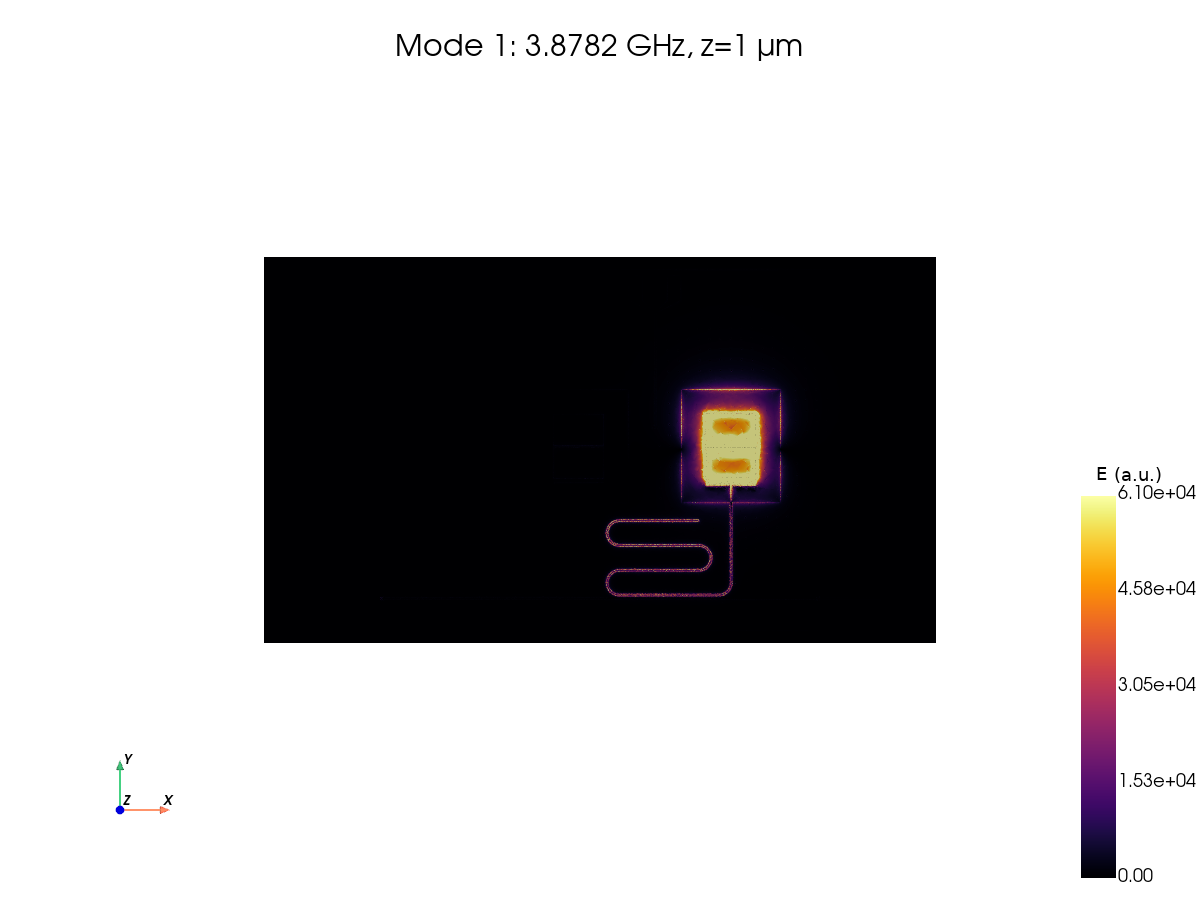

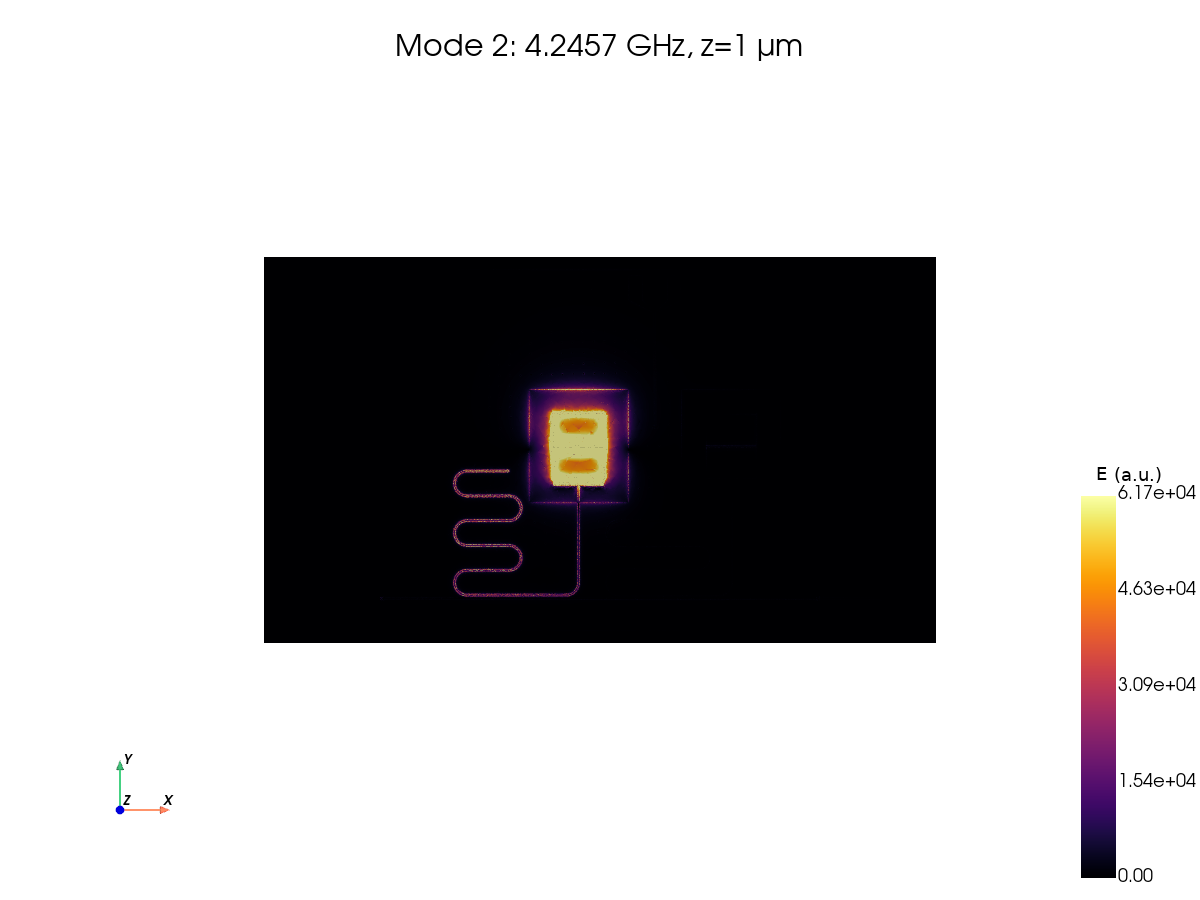

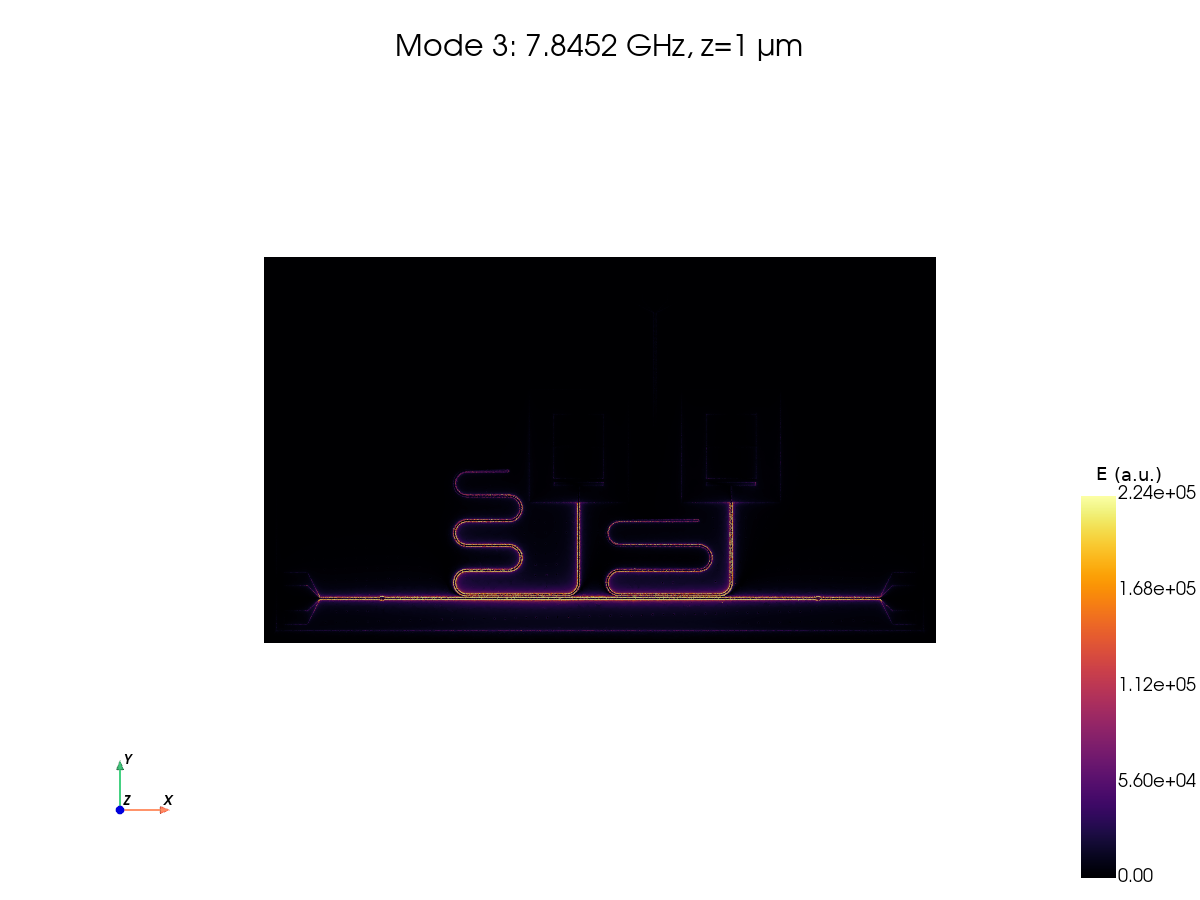

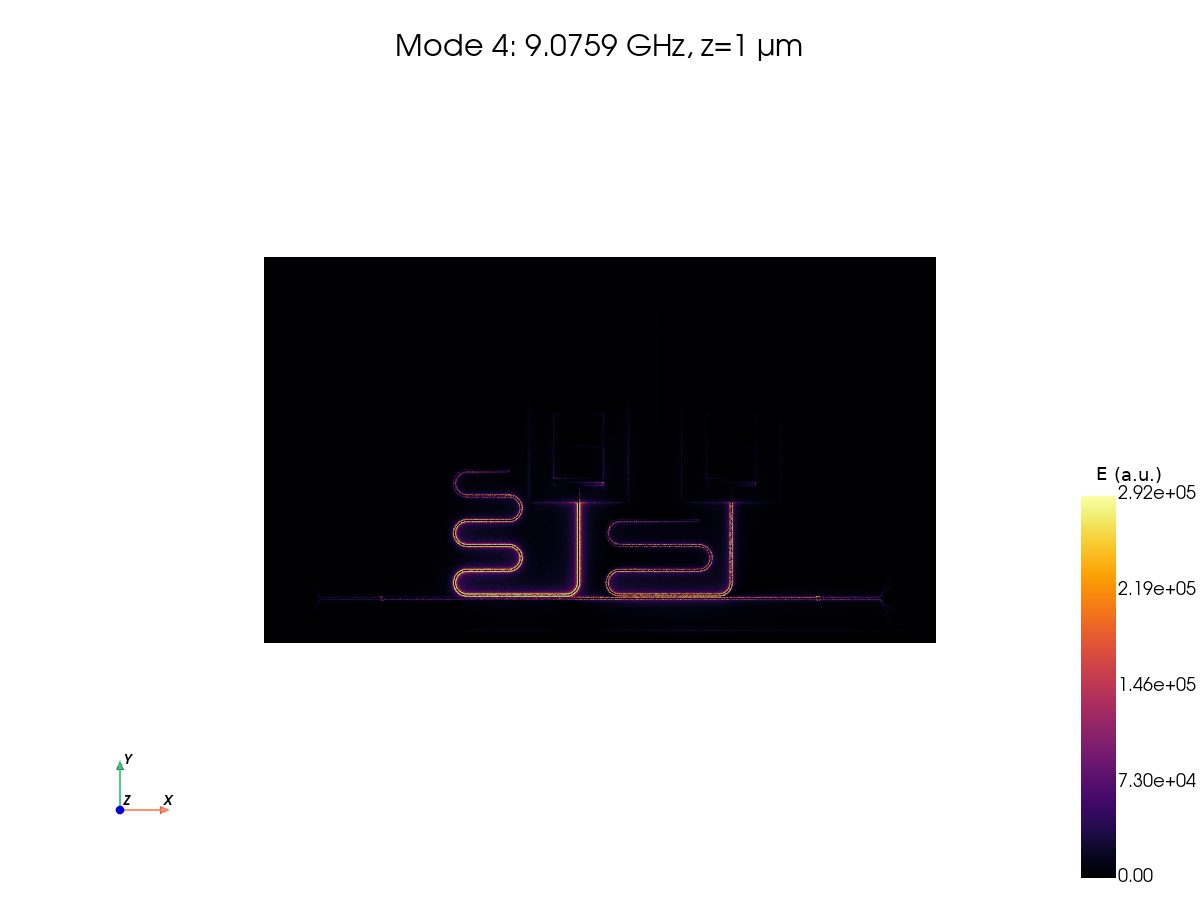

In [ ]:
import numpy as np

from gsim.palace.field_viz import plot_fields_2d
from gsim.palace.results import load_fields

field_slice_z_um = 1.0

saved_frequencies_ghz = eigenmodes["Re{f} (GHz)"].iloc[
    : eigenmode_sim.solver.eigenmode.save
]
for mode_number, frequency_ghz in enumerate(saved_frequencies_ghz, start=1):
    mode_volume = load_fields(eigenmode_results["eig.csv"].parent, mode=mode_number)
    mode_slice = mode_volume.slice(normal="z", origin=(0.0, 0.0, field_slice_z_um))
    del mode_volume
    mode_slice["|E| (a.u.)"] = np.sqrt(
        np.sum(mode_slice["E_real"] ** 2 + mode_slice["E_imag"] ** 2, axis=1)
    )
    plot_fields_2d(
        mode_slice,
        field="|E| (a.u.)",
        normal="z",
        origin=field_slice_z_um,
        cmap="inferno",
        title=f"Mode {mode_number}: {frequency_ghz:.4f} GHz, z={field_slice_z_um:g} µm",
        interactive=False,
    )
    del mode_slice

### Run the driven simulation

Generate a separate mesh for the driven object with the same geometry and
refinement. Sweep 2–10 GHz, excite `o1`, and leave `o2` matched to 50 Ω.
The adaptive sweep builds a reduced model and evaluates the requested output grid.

A narrow resonance may need a smaller frequency span and finer sampling.
Zoom around a feature and compare results across frequency and mesh refinements.
Weakly coupled qubit modes may produce very small features in S21; identify
them with the eigenmode fields and junction participation as well.

In [ ]:
driven_sim.set_driven(
    fmin=driven_fmin_ghz * 1e9,
    fmax=driven_fmax_ghz * 1e9,
    num_points=driven_num_points,
    adaptive_tol=driven_adaptive_tol,
    adaptive_max_samples=driven_adaptive_max_samples,
    reference_impedance=50.0,
    excitation_port="o1",
)
driven_sim.set_output_dir("palace-qpdk-chip/driven")
driven_mesh = driven_sim.mesh(
    refined_mesh_size=refined_mesh_size_um,
    max_mesh_size=max_mesh_size_um,
    fmax=driven_fmax_ghz * 1e9,
    planar_conductors=True,
)
print(f"Tetrahedral elements: {driven_mesh.mesh_stats['tetrahedra']:,}")
frequency_step_khz = (driven_fmax_ghz - driven_fmin_ghz) * 1e6 / (driven_num_points - 1)
print(f"Output frequency spacing: {frequency_step_khz:g} kHz")

In [ ]:
driven_sparams = driven_sim.run(check_cache=True)

### Plot S-parameters

Plot S11 and S21 magnitude and phase. Dotted lines mark eigenfrequencies
within the driven sweep as references for the port-loaded response.

In [ ]:
sparam_figure = driven_sparams.plot_plotly()
for frequency_ghz in eigenmodes["Re{f} (GHz)"]:
    if driven_fmin_ghz <= frequency_ghz <= driven_fmax_ghz:
        sparam_figure.add_vline(
            x=float(frequency_ghz),
            line_dash="dot",
            line_color="gray",
            row="all",
            col=1,
        )
sparam_figure.update_layout(title="Qubit chip: S11 and S21")
sparam_figure